# Marketing Campaign A/B Analysis

**Business question:** Did showing the product advertisement increase purchases compared with showing a public service announcement (PSA)?

This notebook follows the task requirements: compare conversion rates, define hypotheses, run a two-proportion z-test and a chi-square test, interpret the p-value at a 95% confidence level, and complete the rollout and confidence-interval bonus. The source dataset contains user assignment and purchase conversion, but no revenue or campaign cost, so the business impact is expressed as additional conversions rather than profit.

## 1. Load the data and required libraries
Keep `marketing_AB.csv` in the same folder as this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

data = pd.read_csv("marketing_AB.csv")
data.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## 2. Check the dataset
The file includes an exported row index, which is not an analysis field. Remove it, standardize the column names, check missing values and duplicate users, and confirm the group labels and conversion values before testing.

In [2]:
data = data.drop(columns=["Unnamed: 0"], errors="ignore")
data.columns = [
    "user_id", "test_group", "converted", "total_ads",
    "most_ads_day", "most_ads_hour"
]

print("Rows and columns:", data.shape)
print("Missing values:", data.isna().sum().sum())
print("Duplicate user IDs:", data["user_id"].duplicated().sum())
print("Groups:", data["test_group"].value_counts().to_dict())
print("Conversion values:", data["converted"].value_counts().to_dict())

Rows and columns: (588101, 6)
Missing values: 0
Duplicate user IDs: 0
Groups: {'ad': 564577, 'psa': 23524}
Conversion values: {False: 573258, True: 14843}


## 3. Compare conversion rates
Conversion rate is converted users divided by all users in that group. The absolute difference is measured in percentage points; relative lift is the percentage increase over the PSA control rate.

In [3]:
summary = (
    data.groupby("test_group")["converted"]
        .agg(users="size", conversions="sum", conversion_rate="mean")
        .reindex(["psa", "ad"])
)
summary["conversion_rate_pct"] = summary["conversion_rate"] * 100
summary

,users,conversions,conversion_rate,conversion_rate_pct
test_group,,,,
psa,23524,420,0.017854,1.785411
ad,564577,14423,0.025547,2.554656


In [4]:
control_rate = summary.loc["psa", "conversion_rate"]
ad_rate = summary.loc["ad", "conversion_rate"]
absolute_lift = ad_rate - control_rate
relative_lift = absolute_lift / control_rate

print(f"PSA conversion rate: {control_rate:.4%}")
print(f"Ad conversion rate: {ad_rate:.4%}")
print(f"Absolute lift: {absolute_lift:.4%} ({absolute_lift*100:.3f} percentage points)")
print(f"Relative lift: {relative_lift:.2%}")

PSA conversion rate: 1.7854%
Ad conversion rate: 2.5547%
Absolute lift: 0.7692% (0.769 percentage points)
Relative lift: 43.09%


## 4. Test statistical significance
**H₀:** the ad and PSA conversion rates are equal.

**H₁:** the conversion rates differ.

Use a two-sided two-proportion z-test at α = 0.05. The chi-square test on the same 2×2 table is an independent check of the same association. A small p-value is evidence against H₀; it does not by itself measure business importance or prove causality if assignment was not random.

In [5]:
conversions = np.array([summary.loc["ad", "conversions"], summary.loc["psa", "conversions"]])
users = np.array([summary.loc["ad", "users"], summary.loc["psa", "users"]])
z_stat, z_pvalue = proportions_ztest(conversions, users, alternative="two-sided")

contingency = pd.crosstab(data["test_group"], data["converted"]).reindex(index=["ad", "psa"], columns=[True, False])
chi2_stat, chi2_pvalue, dof, expected = chi2_contingency(contingency)

print("Contingency table (rows=group; columns=converted, not converted):")
display(contingency)
print(f"Z-test: z = {z_stat:.3f}, p-value = {z_pvalue:.3g}")
print(f"Chi-square: chi2 = {chi2_stat:.3f}, df = {dof}, p-value = {chi2_pvalue:.3g}")
print("Decision at 5%:", "Reject H0" if z_pvalue < 0.05 else "Do not reject H0")

Contingency table (rows=group; columns=converted, not converted):


converted,True,False
test_group,,
ad,14423,550154
psa,420,23104


Z-test: z = 7.370, p-value = 1.71e-13
Chi-square: chi2 = 54.006, df = 1, p-value = 2e-13
Decision at 5%: Reject H0


## 5. 95% confidence intervals and lift visualization (bonus)
Wilson intervals are used for each group’s conversion rate. The difference interval uses the Newcombe method, built from the two Wilson intervals. It is shown in percentage points, alongside zero as the no-lift reference.

In [6]:
ad_ci = proportion_confint(int(summary.loc["ad", "conversions"]), int(summary.loc["ad", "users"]), method="wilson")
psa_ci = proportion_confint(int(summary.loc["psa", "conversions"]), int(summary.loc["psa", "users"]), method="wilson")

# Newcombe confidence interval for difference in independent proportions
lo = ad_rate - control_rate - np.sqrt((ad_rate-ad_ci[0])**2 + (psa_ci[1]-control_rate)**2)
hi = ad_rate - control_rate + np.sqrt((ad_ci[1]-ad_rate)**2 + (control_rate-psa_ci[0])**2)

ci_table = pd.DataFrame({
    "Group": ["PSA (control)", "Ad (test)"],
    "Rate": [control_rate, ad_rate],
    "95% CI low": [psa_ci[0], ad_ci[0]],
    "95% CI high": [psa_ci[1], ad_ci[1]]
})
ci_table.style.format({"Rate":"{:.3%}", "95% CI low":"{:.3%}", "95% CI high":"{:.3%}"})

,Group,Rate,95% CI low,95% CI high
0,PSA (control),1.785%,1.624%,1.963%
1,Ad (test),2.555%,2.514%,2.596%


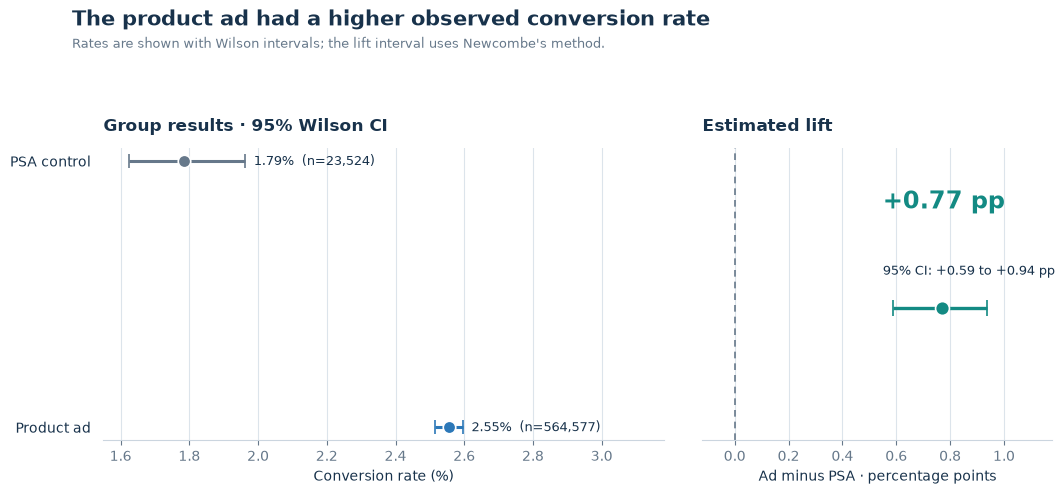

Ad minus PSA lift: 0.769%
95% CI for lift: 0.587% to 0.936%


In [7]:
fig, (ax_rate, ax_lift) = plt.subplots(
    1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1.6, 1]}
)

navy = "#18324B"
blue = "#2C78B8"
teal = "#138A83"
muted = "#66788A"

# Compare each group's conversion rate and its 95% Wilson interval.
groups = [
    ("PSA control", control_rate, psa_ci, int(summary.loc["psa", "users"]), muted),
    ("Product ad", ad_rate, ad_ci, int(summary.loc["ad", "users"]), blue),
]
for y, (label, rate, ci, n_users, color) in enumerate(groups):
    ax_rate.errorbar(
        rate * 100, y,
        xerr=[[(rate - ci[0]) * 100], [(ci[1] - rate) * 100]],
        fmt="o", markersize=9, capsize=5, color=color, linewidth=2.2,
        markeredgecolor="white", markeredgewidth=1.2, zorder=3
    )
    ax_rate.text(
        ci[1] * 100 + 0.025, y, f"{rate:.2%}  (n={n_users:,})",
        va="center", ha="left", fontsize=9, color=navy
    )

ax_rate.set_yticks([0, 1], ["PSA control", "Product ad"])
ax_rate.invert_yaxis()
ax_rate.set_xlim(1.55, 3.18)
ax_rate.set_xlabel("Conversion rate (%)", color=navy)
ax_rate.set_title("Group results · 95% Wilson CI", loc="left", color=navy, weight="bold", pad=12)
ax_rate.grid(axis="x", color="#DCE4EB", linewidth=0.8)
ax_rate.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax_rate.spines[spine].set_visible(False)
ax_rate.spines["bottom"].set_color("#CBD5DF")
ax_rate.tick_params(axis="y", length=0, colors=navy, pad=9)
ax_rate.tick_params(axis="x", colors=muted)

# Show the treatment effect directly; zero marks no difference.
lift_pp = absolute_lift * 100
lo_pp = lo * 100
hi_pp = hi * 100
ax_lift.axvline(0, color=muted, linewidth=1.2, linestyle=(0, (4, 3)))
ax_lift.errorbar(
    lift_pp, 0,
    xerr=[[(lift_pp - lo_pp)], [(hi_pp - lift_pp)]],
    fmt="o", markersize=10, capsize=6, color=teal, linewidth=2.4,
    markeredgecolor="white", markeredgewidth=1.2, zorder=3
)
ax_lift.text(0.55, 0.36, f"+{lift_pp:.2f} pp", color=teal, fontsize=17, weight="bold")
ax_lift.text(0.55, 0.12, f"95% CI: +{lo_pp:.2f} to +{hi_pp:.2f} pp", color=navy, fontsize=9)
ax_lift.set_xlim(-0.12, 1.18)
ax_lift.set_ylim(-0.48, 0.58)
ax_lift.set_yticks([])
ax_lift.set_xlabel("Ad minus PSA · percentage points", color=navy)
ax_lift.set_title("Estimated lift", loc="left", color=navy, weight="bold", pad=12)
ax_lift.grid(axis="x", color="#DCE4EB", linewidth=0.8)
ax_lift.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax_lift.spines[spine].set_visible(False)
ax_lift.spines["bottom"].set_color("#CBD5DF")
ax_lift.tick_params(axis="x", colors=muted)

fig.suptitle("The product ad had a higher observed conversion rate", x=0.07, ha="left", y=1.02,
             fontsize=15, color=navy, weight="bold")
fig.text(0.07, 0.94, "Rates are shown with Wilson intervals; the lift interval uses Newcombe's method.",
         fontsize=9, color=muted)
fig.patch.set_facecolor("white")
plt.tight_layout(rect=[0, 0, 1, 0.90], w_pad=2.8)
plt.show()

print(f"Ad minus PSA lift: {absolute_lift:.3%}")
print(f"95% CI for lift: {lo:.3%} to {hi:.3%}")

## 6. Rollout estimate (bonus)
If the observed absolute lift stayed the same when the ad was shown to 100,000 users, the estimated extra conversions would be lift × 100,000. This is a scenario estimate, not a guaranteed forecast; it assumes comparable users, stable delivery, and the same conversion effect at scale.

In [8]:
rollout_users = 100_000
extra_conversions = absolute_lift * rollout_users
print(f"Estimated conversions at PSA rate: {control_rate*rollout_users:,.0f}")
print(f"Estimated conversions at ad rate: {ad_rate*rollout_users:,.0f}")
print(f"Estimated additional conversions from the ad: {extra_conversions:,.0f} per 100,000 users")
print(f"95% CI for additional conversions: {lo*rollout_users:,.0f} to {hi*rollout_users:,.0f}")

Estimated conversions at PSA rate: 1,785
Estimated conversions at ad rate: 2,555
Estimated additional conversions from the ad: 769 per 100,000 users
95% CI for additional conversions: 587 to 936


## 7. Conclusion
The statistical decision is based on the two-sided z-test and the 5% threshold. Report the observed conversion rates, percentage-point lift, confidence interval, and p-value together. Recommend a rollout only if the confidence interval supports a positive effect and the business accepts the assumptions behind extrapolating to a larger audience. This dataset has no spend, margin, or revenue fields, so it cannot establish profitability or return on ad spend.